In [7]:
import os
import time
import math
import random
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [4]:
import os
import random
import warnings
import numpy as np
import torch
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

SEEDS = [0, 1, 2]
SPLIT_SEED = 42
SHIFT_SEED = 1234
EPOCHS = 60
BATCH_SIZE = 50
NUM_CLASSES = 10
OFFICIAL_SHIFTED_PATH = None

OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"

if device == "cpu":
    torch.set_num_threads(os.cpu_count() or 1)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10
})

CLASSES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Device:", device)
print("PyTorch:", torch.__version__)
print("Seeds:", SEEDS)
print("Maximum epochs:", EPOCHS)

Device: cuda
PyTorch: 2.11.0+cu130
Seeds: [0, 1, 2]
Maximum epochs: 60


In [5]:
def load_cifar10():
    if os.path.exists("cifar10.npz"):
        data = np.load("cifar10.npz")
        return data["x_train"], data["y_train"], data["x_test"], data["y_test"]

    from torchvision.datasets import CIFAR10

    train_data = CIFAR10("./data", train=True, download=True)
    test_data = CIFAR10("./data", train=False, download=True)

    x_train = train_data.data
    y_train = np.array(train_data.targets)
    x_test = test_data.data
    y_test = np.array(test_data.targets)

    np.savez_compressed(
        "cifar10.npz",
        x_train=x_train,
        y_train=y_train,
        x_test=x_test,
        y_test=y_test
    )

    return x_train, y_train, x_test, y_test


x_train_full, y_train_full, x_test_np, y_test_np = load_cifar10()

print("Full train:", x_train_full.shape, "| Test:", x_test_np.shape)

rng = np.random.RandomState(SPLIT_SEED)
tr_idx, va_idx = [], []

for c in range(NUM_CLASSES):
    idx = rng.permutation(np.where(y_train_full == c)[0])[:50]
    tr_idx.extend(idx[:40])
    va_idx.extend(idx[40:])

tr_idx = np.array(tr_idx)
va_idx = np.array(va_idx)


def to_t(x):
    return torch.from_numpy(x).permute(0, 3, 1, 2).float() / 255.0


Xtr = to_t(x_train_full[tr_idx])
Ytr = torch.from_numpy(y_train_full[tr_idx])

Xva = to_t(x_train_full[va_idx])
Yva = torch.from_numpy(y_train_full[va_idx])

Xclean = to_t(x_test_np)
Yclean = torch.from_numpy(y_test_np)

print("Train:", tuple(Xtr.shape), np.bincount(Ytr.numpy()))
print("Validation:", tuple(Xva.shape), np.bincount(Yva.numpy()))

MEAN = Xtr.mean((0, 2, 3)).view(1, 3, 1, 1)
STD = Xtr.std((0, 2, 3)).view(1, 3, 1, 1)

print("Mean:", MEAN.flatten().numpy().round(3))
print("Std:", STD.flatten().numpy().round(3))

100%|██████████| 170M/170M [42:46<00:00, 66.4kB/s]


Full train: (50000, 32, 32, 3) | Test: (10000, 32, 32, 3)
Train: (400, 3, 32, 32) [40 40 40 40 40 40 40 40 40 40]
Validation: (100, 3, 32, 32) [10 10 10 10 10 10 10 10 10 10]
Mean: [0.489 0.485 0.456]
Std: [0.253 0.246 0.264]


Shifted test built in 4.0s | Channel-swapped images: 49.9% | Mean occlusion: 25.0%


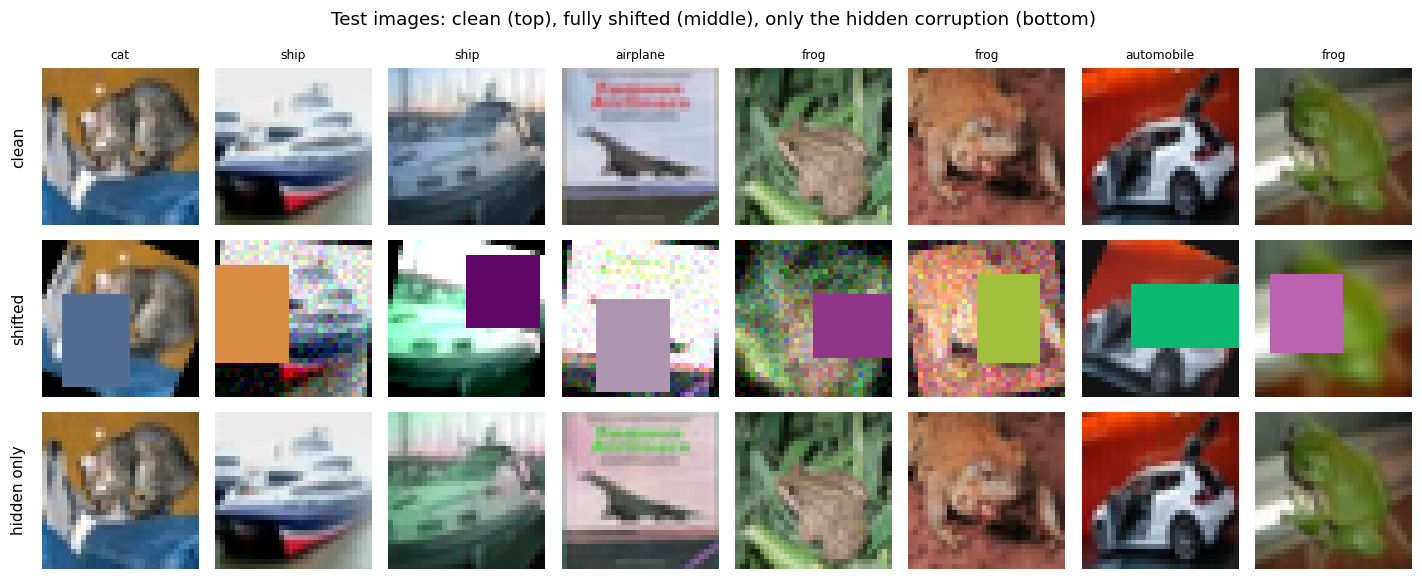

In [8]:
def gaussian_kernel(k=5, sigma=1.0):
    ax = torch.arange(k).float() - (k - 1) / 2
    g = torch.exp(-(ax ** 2) / (2 * sigma ** 2))
    g = g / g.sum()

    return (g[:, None] * g[None, :]).view(1, 1, k, k)


def blur_batch(x, sigma=1.0, k=5):
    kernel = gaussian_kernel(k, sigma).to(x.device)
    kernel = kernel.repeat(3, 1, 1, 1)

    x = F.pad(x, (k // 2,) * 4, mode="reflect")
    return F.conv2d(x, kernel, groups=3)


def affine_batch(x, angle_rad, scale, tx, ty, flip):
    c = torch.cos(angle_rad) / scale
    s = torch.sin(angle_rad) / scale

    theta = torch.zeros(x.size(0), 2, 3, device=x.device)

    theta[:, 0, 0] = c * flip
    theta[:, 0, 1] = -s
    theta[:, 0, 2] = tx

    theta[:, 1, 0] = s * flip
    theta[:, 1, 1] = c
    theta[:, 1, 2] = ty

    grid = F.affine_grid(theta, list(x.shape), align_corners=False)

    return F.grid_sample(
        x,
        grid,
        mode="bilinear",
        padding_mode="zeros",
        align_corners=False
    )


def rect_mask(n, H, W, top, left, h, w, dev):
    ys = torch.arange(H, device=dev).view(1, H, 1)
    xs = torch.arange(W, device=dev).view(1, 1, W)

    top, left, h, w = [
        value.view(-1, 1, 1)
        for value in (top, left, h, w)
    ]

    mask = (
        (ys >= top) &
        (ys < top + h) &
        (xs >= left) &
        (xs < left + w)
    )

    return mask.unsqueeze(1)


PERMS = torch.tensor([
    [0, 2, 1],
    [1, 0, 2],
    [1, 2, 0],
    [2, 0, 1],
    [2, 1, 0]
])


def make_shifted(
    x,
    seed=SHIFT_SEED,
    steps=("rot", "photo", "blur", "noise", "hidden", "occ")
):
    generator = torch.Generator().manual_seed(seed)

    n, _, H, W = x.shape

    def rand(*shape):
        return torch.rand(*shape, generator=generator)

    angle = (rand(n) * 2 - 1) * 25.0

    brightness = 0.5 + rand(n)
    contrast = 0.6 + 0.8 * rand(n)

    blur_mask = rand(n) < 0.3
    noise_mask = rand(n) < 0.3

    hidden_mask = rand(n) < 0.5
    hidden_kind = (rand(n) * 5).long().clamp(max=4)

    area = 0.20 + 0.10 * rand(n)
    aspect = 0.6 + rand(n)

    top_random = rand(n)
    left_random = rand(n)
    color = rand(n, 3)

    noise = torch.randn(x.shape, generator=generator) * 0.08

    out = x.clone()

    if "rot" in steps:
        zeros = torch.zeros(n)

        out = affine_batch(
            out,
            angle * math.pi / 180,
            torch.ones(n),
            zeros,
            zeros,
            torch.ones(n)
        )

    if "photo" in steps:
        mean = out.mean((1, 2, 3), keepdim=True)

        out = (
            (out - mean) * contrast.view(-1, 1, 1, 1) + mean
        ) * brightness.view(-1, 1, 1, 1)

        out = out.clamp(0, 1)

    if "blur" in steps:
        out = torch.where(
            blur_mask.view(-1, 1, 1, 1),
            blur_batch(out),
            out
        )

    if "noise" in steps:
        out = torch.where(
            noise_mask.view(-1, 1, 1, 1),
            (out + noise).clamp(0, 1),
            out
        )

    if "hidden" in steps:
        for k in range(5):
            selected = hidden_mask & (hidden_kind == k)

            if selected.any():
                out[selected] = out[selected][:, PERMS[k]]

    if "occ" in steps:
        h = torch.sqrt(area * H * W * aspect)
        h = h.round().clamp(4, H).long()

        w = area * H * W / h.float()
        w = w.round().clamp(4, W).long()

        top = (
            top_random * (H - h + 1).float()
        ).floor().long()

        left = (
            left_random * (W - w + 1).float()
        ).floor().long()

        mask = rect_mask(
            n, H, W, top, left, h, w, out.device
        )

        out = torch.where(
            mask,
            color.view(n, 3, 1, 1),
            out
        )

    metadata = {
        "angle": angle.numpy(),
        "bright": brightness.numpy(),
        "contrast": contrast.numpy(),
        "blur": blur_mask.numpy(),
        "noise": noise_mask.numpy(),
        "swapped": hidden_mask.numpy(),
        "occ_area": (
            (h * w).float().numpy() / (H * W)
            if "occ" in steps else None
        )
    }

    return out.clamp(0, 1), metadata


t0 = time.time()

if OFFICIAL_SHIFTED_PATH:
    if OFFICIAL_SHIFTED_PATH.endswith(".pt"):
        data = torch.load(OFFICIAL_SHIFTED_PATH)
    else:
        data = np.load(OFFICIAL_SHIFTED_PATH)

    Xshift = (
        data["x"].float()
        if torch.is_tensor(data["x"])
        else to_t(np.asarray(data["x"]))
    )

    Yshift = (
        torch.as_tensor(np.asarray(data["y"])).long()
        if "y" in data
        else Yclean
    )

    shift_meta = None

else:
    Xshift, shift_meta = make_shifted(Xclean)
    Yshift = Yclean


Xhidden_only, _ = make_shifted(
    Xclean,
    steps=("hidden",)
)


if shift_meta is not None:
    print(
        f"Shifted test built in {time.time() - t0:.1f}s"
        f" | Channel-swapped images: "
        f"{shift_meta['swapped'].mean():.1%}"
        f" | Mean occlusion: "
        f"{shift_meta['occ_area'].mean():.1%}"
    )
else:
    print("Official shifted test loaded:", tuple(Xshift.shape))


fig, ax = plt.subplots(3, 8, figsize=(13, 5.4))

for j in range(8):
    ax[0, j].imshow(Xclean[j].permute(1, 2, 0))
    ax[1, j].imshow(Xshift[j].permute(1, 2, 0).cpu())
    ax[2, j].imshow(Xhidden_only[j].permute(1, 2, 0))

    ax[0, j].set_title(CLASSES[Yclean[j]], fontsize=8)

    for r in range(3):
        ax[r, j].axis("off")


ax[0, 0].text(
    -0.1, 0.5, "clean",
    transform=ax[0, 0].transAxes,
    rotation=90, va="center", ha="right"
)

ax[1, 0].text(
    -0.1, 0.5, "shifted",
    transform=ax[1, 0].transAxes,
    rotation=90, va="center", ha="right"
)

ax[2, 0].text(
    -0.1, 0.5, "hidden only",
    transform=ax[2, 0].transAxes,
    rotation=90, va="center", ha="right"
)

fig.suptitle(
    "Test images: clean (top), fully shifted (middle), "
    "only the hidden corruption (bottom)"
)

plt.tight_layout()
plt.show()

In [11]:
import torch
import torch.nn as nn

NUM_CLASSES = 10

In [12]:
class CBR(nn.Sequential):
    def __init__(self, cin, cout, k, p=0):
        super().__init__(
            nn.Conv2d(cin, cout, k, padding=p, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True)
        )


class Inception(nn.Module):
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()

        self.b1 = CBR(cin, c1, 1)

        self.b3 = nn.Sequential(
            CBR(cin, c3r, 1),
            CBR(c3r, c3, 3, 1)
        )

        self.b5 = nn.Sequential(
            CBR(cin, c5r, 1),
            CBR(c5r, c5, 5, 2)
        )

        self.bp = nn.Sequential(
            nn.MaxPool2d(3, 1, 1),
            CBR(cin, cp, 1)
        )

        self.cout = c1 + c3 + c5 + cp

    def forward(self, x):
        out1 = self.b1(x)
        out3 = self.b3(x)
        out5 = self.b5(x)
        outp = self.bp(x)

        return torch.cat([out1, out3, out5, outp], dim=1)


class Net(nn.Module):
    def __init__(self, drop=0.3, nc=NUM_CLASSES):
        super().__init__()

        self.stem = nn.Sequential(
            CBR(3, 32, 5, 2),
            nn.MaxPool2d(2)
        )

        self.inc1 = Inception(32, 16, 16, 24, 4, 8, 8)
        self.inc2 = Inception(56, 32, 24, 48, 8, 16, 16)
        self.inc3 = Inception(112, 48, 32, 64, 8, 24, 24)

        self.pool = nn.MaxPool2d(2)
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(160, nc)

    def forward(self, x):
        x = self.stem(x)
        x = self.pool(self.inc1(x))
        x = self.pool(self.inc2(x))
        x = self.inc3(x)

        x = x.mean(dim=(2, 3))
        x = self.drop(x)

        return self.fc(x)


def count_params(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


model = Net()
n_params = count_params(model)

print(f"Trainable parameters: {n_params:,} (limit: 1,000,000)")

assert n_params <= 1_000_000

layers = [
    ("stem", model.stem),
    ("inc1", model.inc1),
    ("inc2", model.inc2),
    ("inc3", model.inc3),
    ("fc", model.fc)
]

for name, layer in layers:
    print(f"{name:5s} {count_params(layer):>9,}")

with torch.no_grad():
    model.eval()
    output = model(torch.zeros(4, 3, 32, 32))
    print("Output shape for a batch of 4:", tuple(output.shape))

del model

Trainable parameters: 64,402 (limit: 1,000,000)
stem      2,464
inc1      5,816
inc2     18,336
inc3     36,176
fc        1,610
Output shape for a batch of 4: (4, 10)


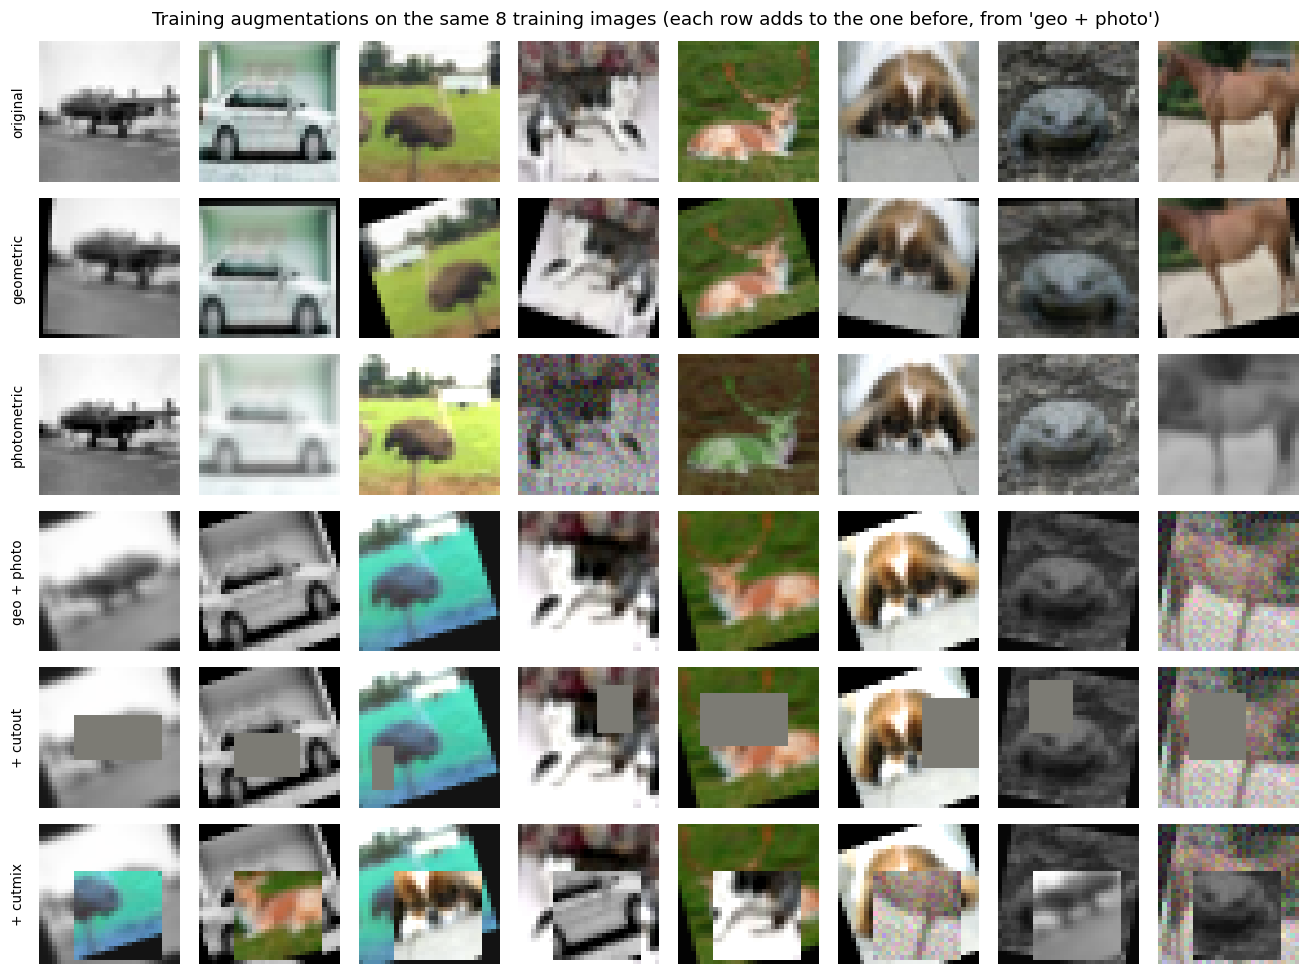

In [13]:
def aug_geometric(
    x, rot=20.0, scale=(0.85, 1.15),
    shift=4, hflip=True, vflip=False
):
    n = x.size(0)
    d = x.device

    def rand():
        return torch.rand(n, device=d) * 2 - 1

    angle = rand() * rot * math.pi / 180

    scale_factor = scale[0] + (
        (rand() + 1) / 2
    ) * (scale[1] - scale[0])

    tx = rand() * shift / 16
    ty = rand() * shift / 16

    if hflip:
        flip = torch.where(
            torch.rand(n, device=d) < 0.5,
            -1.0,
            1.0
        )
    else:
        flip = torch.ones(n, device=d)

    out = affine_batch(x, angle, scale_factor, tx, ty, flip)

    if vflip:
        mask = (
            torch.rand(n, device=d) < 0.5
        ).view(-1, 1, 1, 1)

        out = torch.where(mask, out.flip(2), out)

    return out


def aug_photometric(
    x, bright=0.4, contrast=0.4, sat=0.4,
    p_gray=0.2, p_shuffle=0.2,
    p_blur=0.2, p_noise=0.2, noise_std=0.06
):
    n = x.size(0)
    d = x.device

    def jitter(amount):
        return 1 + (
            torch.rand(n, 1, 1, 1, device=d) * 2 - 1
        ) * amount

    def select(probability):
        return torch.rand(n, 1, 1, 1, device=d) < probability

    def grayscale(t):
        return (
            0.299 * t[:, 0:1]
            + 0.587 * t[:, 1:2]
            + 0.114 * t[:, 2:3]
        )

    x = x * jitter(bright)

    mean = x.mean((1, 2, 3), keepdim=True)
    x = ((x - mean) * jitter(contrast) + mean).clamp(0, 1)

    gray = grayscale(x)
    x = ((x - gray) * jitter(sat) + gray).clamp(0, 1)

    gray_images = grayscale(x).expand(-1, 3, -1, -1)
    x = torch.where(select(p_gray), gray_images, x)

    permutation = torch.rand(n, 3, device=d).argsort(1)

    shuffled = torch.gather(
        x,
        1,
        permutation.view(n, 3, 1, 1).expand(
            -1, -1, x.size(2), x.size(3)
        )
    )

    x = torch.where(select(p_shuffle), shuffled, x)

    x = torch.where(
        select(p_blur),
        blur_batch(x, sigma=0.8),
        x
    )

    noisy = (x + torch.randn_like(x) * noise_std).clamp(0, 1)
    x = torch.where(select(p_noise), noisy, x)

    return x


def aug_cutout(x, p=0.5, lo=0.05, hi=0.25):
    n, _, H, W = x.shape
    d = x.device

    area = lo + (hi - lo) * torch.rand(n, device=d)
    aspect = 0.5 + 1.5 * torch.rand(n, device=d)

    h = torch.sqrt(area * H * W * aspect)
    h = h.round().clamp(2, H).long()

    w = area * H * W / h.float()
    w = w.round().clamp(2, W).long()

    top = (
        torch.rand(n, device=d) * (H - h + 1).float()
    ).floor().long()

    left = (
        torch.rand(n, device=d) * (W - w + 1).float()
    ).floor().long()

    mask = rect_mask(n, H, W, top, left, h, w, d)

    apply_mask = torch.rand(n, 1, 1, 1, device=d) < p
    mask = mask & apply_mask

    return x.masked_fill(mask, 0.0)


def cutmix(x, y_soft, alpha=1.0, p=0.5):
    if np.random.rand() > p:
        return x, y_soft

    n, _, H, W = x.shape

    lam = np.random.beta(alpha, alpha)
    permutation = torch.randperm(n, device=x.device)

    rh = int(round(H * math.sqrt(1 - lam)))
    rw = int(round(W * math.sqrt(1 - lam)))

    cy = np.random.randint(H)
    cx = np.random.randint(W)

    y1 = max(cy - rh // 2, 0)
    y2 = min(cy + rh // 2, H)
    x1 = max(cx - rw // 2, 0)
    x2 = min(cx + rw // 2, W)

    x = x.clone()
    x[:, :, y1:y2, x1:x2] = (
        x[permutation][:, :, y1:y2, x1:x2]
    )

    lam_adj = 1 - (
        (y2 - y1) * (x2 - x1)
    ) / (H * W)

    y_soft = (
        lam_adj * y_soft
        + (1 - lam_adj) * y_soft[permutation]
    )

    return x, y_soft


# Data on the compute device
def dv(t):
    return t.to(device)


MEAN_d = dv(MEAN)
STD_d = dv(STD)

def norm(t):
    return (t - MEAN) / STD


Xtr_d = dv(Xtr)
Ytr_d = dv(Ytr)

Xtr_n, Xva_n, Xcl_n, Xsh_n, Xhid_n = [
    dv(norm(t))
    for t in (Xtr, Xva, Xclean, Xshift, Xhidden_only)
]

Xcl_raw = dv(Xclean)
Xsh_raw = dv(Xshift)


# Visual check of augmentations
set_seed(0)

indices = [0, 41, 82, 123, 164, 205, 246, 287]

xb = Xtr_d[indices]

ysoft = F.one_hot(
    Ytr_d[indices],
    NUM_CLASSES
).float()

geometric = aug_geometric(xb)
photometric = aug_photometric(xb)
geo_photo = aug_photometric(aug_geometric(xb))

rows = [
    ("original", xb),
    ("geometric", geometric),
    ("photometric", photometric),
    ("geo + photo", geo_photo)
]

xn = (geo_photo - MEAN_d) / STD_d

cutout_images = aug_cutout(xn, p=1.0) * STD_d + MEAN_d
rows.append(("+ cutout", cutout_images))

cutmix_images, _ = cutmix(xn, ysoft, p=1.0)
rows.append(("+ cutmix", cutmix_images * STD_d + MEAN_d))


fig, ax = plt.subplots(len(rows), 8, figsize=(12, 9))

for r, (name, images) in enumerate(rows):
    for c in range(8):
        ax[r, c].imshow(
            images[c].clamp(0, 1).permute(1, 2, 0).cpu()
        )
        ax[r, c].axis("off")

    ax[r, 0].text(
        -0.1, 0.5, name,
        transform=ax[r, 0].transAxes,
        rotation=90,
        va="center",
        ha="right",
        fontsize=9
    )

fig.suptitle(
    "Training augmentations on the same 8 training images "
    "(each row adds to the one before, from 'geo + photo')"
)

plt.tight_layout()
plt.show()

In [14]:
import pickle
import pandas as pd

USE_CACHE = True

def make_cfg(**kwargs):
    config = {
        "geo": False,
        "photo": False,
        "cutout": False,
        "cutmix": False,
        "ls": 0.0,
        "vflip": False,
        "rot": 20.0,
        "color_inv": True
    }

    config.update(kwargs)
    return config


HP_DEFAULT = {
    "lr": 0.05,
    "wd": 5e-4,
    "drop": 0.3,
    "patience": 25
}


def evaluate(model, X, Y, bs=1000):
    model.eval()
    predictions = []
    total_loss = 0.0

    with torch.no_grad():
        for i in range(0, len(X), bs):
            xb = X[i:i + bs]
            yb = Y[i:i + bs].to(X.device)

            logits = model(xb)

            total_loss += F.cross_entropy(
                logits, yb, reduction="sum"
            ).item()

            predictions.append(logits.argmax(1).cpu())

    predictions = torch.cat(predictions)

    accuracy = (predictions == Y.cpu()).float().mean().item()
    average_loss = total_loss / len(X)

    return accuracy, average_loss, predictions.numpy()


def train_one(cfg, seed, hp, epochs=EPOCHS, eval_test=True):
    set_seed(seed)
    start_time = time.time()

    model = Net(hp["drop"]).to(device)

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=hp["lr"],
        momentum=0.9,
        nesterov=True,
        weight_decay=hp["wd"]
    )

    steps_per_epoch = math.ceil(len(Xtr_d) / BATCH_SIZE)

    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=hp["lr"],
        epochs=epochs,
        steps_per_epoch=steps_per_epoch,
        pct_start=0.2
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "lr": []
    }

    best_acc = -1
    best_loss = 1e9
    best_epoch = 0
    bad_epochs = 0
    best_state = None

    for epoch in range(epochs):
        model.train()

        order = torch.randperm(len(Xtr_d)).to(device)

        for i in range(0, len(order), BATCH_SIZE):
            indices = order[i:i + BATCH_SIZE]

            xb = Xtr_d[indices]
            yb = Ytr_d[indices]

            ysoft = (
                F.one_hot(yb, NUM_CLASSES).float()
                * (1 - cfg["ls"])
                + cfg["ls"] / NUM_CLASSES
            )

            if cfg["geo"]:
                xb = aug_geometric(
                    xb,
                    rot=cfg["rot"],
                    vflip=cfg["vflip"]
                )

            if cfg["photo"]:
                photo_cfg = (
                    {}
                    if cfg["color_inv"]
                    else {
                        "p_gray": 0.0,
                        "p_shuffle": 0.0
                    }
                )

                xb = aug_photometric(xb, **photo_cfg)

            xb = (xb - MEAN_d) / STD_d

            if cfg["cutout"]:
                xb = aug_cutout(xb)

            if cfg["cutmix"]:
                xb, ysoft = cutmix(xb, ysoft)

            logits = model(xb)

            loss = -(
                ysoft * F.log_softmax(logits, dim=1)
            ).sum(1).mean()

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            scheduler.step()

        train_acc, train_loss, _ = evaluate(
            model, Xtr_n, Ytr_d
        )

        val_acc, val_loss, _ = evaluate(
            model, Xva_n, Yva
        )

        values = [
            train_loss,
            train_acc,
            val_loss,
            val_acc,
            optimizer.param_groups[0]["lr"]
        ]

        for key, value in zip(history, values):
            history[key].append(value)

        if (
            val_acc > best_acc
            or (
                val_acc == best_acc
                and val_loss < best_loss - 1e-4
            )
        ):
            best_acc = val_acc
            best_loss = val_loss
            best_epoch = epoch
            bad_epochs = 0

            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        else:
            bad_epochs += 1

            if bad_epochs >= hp["patience"]:
                break

    model.load_state_dict(best_state)

    train_acc, _, _ = evaluate(model, Xtr_n, Ytr_d)
    val_acc, val_loss, _ = evaluate(model, Xva_n, Yva)

    if eval_test:
        clean_acc, _, _ = evaluate(model, Xcl_n, Yclean)
        shift_acc, _, shift_pred = evaluate(
            model, Xsh_n, Yshift
        )
    else:
        clean_acc = float("nan")
        shift_acc = float("nan")
        shift_pred = None

    return {
        "hist": history,
        "best_ep": best_epoch,
        "epochs_run": len(history["val_acc"]),
        "train_acc": train_acc,
        "val_acc": val_acc,
        "val_loss": val_loss,
        "clean_acc": clean_acc,
        "shift_acc": shift_acc,
        "shift_pred": shift_pred,
        "state": best_state,
        "hp": hp,
        "cfg": cfg,
        "seed": seed,
        "secs": time.time() - start_time
    }


def run_cached(tag, cfg, seed, hp=HP_DEFAULT, eval_test=True):
    path = os.path.join(
        OUT_DIR,
        f"run_{tag}_s{seed}.pkl"
    )

    cached = USE_CACHE and os.path.exists(path)

    if cached:
        with open(path, "rb") as file:
            result = pickle.load(file)
    else:
        result = train_one(
            cfg, seed, hp, eval_test=eval_test
        )

        with open(path, "wb") as file:
            pickle.dump(result, file)

    head = (
        f"  [{tag} | seed {seed}] "
        f"best epoch {result['best_ep'] + 1:2d}/"
        f"{result['epochs_run']} | "
        f"train {result['train_acc']:.3f} "
        f"val {result['val_acc']:.3f} "
    )

    if eval_test:
        tail = (
            f"clean {result['clean_acc']:.3f} "
            f"shifted {result['shift_acc']:.3f}"
        )
    else:
        tail = "(test sets not evaluated)"

    tail += f" | {result['secs']:.0f}s"

    if cached:
        tail += " (loaded from results/)"

    print(head + tail)

    return result


def run_all(tag, cfg, hp=HP_DEFAULT, seeds=SEEDS):
    return [
        run_cached(tag, cfg, seed, hp)
        for seed in seeds
    ]


def ms(values):
    return (
        f"{100 * np.mean(values):.1f} "
        f"± {100 * np.std(values):.1f}"
    )


CFG = {
    "No augmentation": make_cfg(),

    "Geometric only (crop, flip, rotation)":
        make_cfg(geo=True),

    "Photometric only (jitter, blur, noise)":
        make_cfg(photo=True),

    "Geometric + photometric":
        make_cfg(geo=True, photo=True),

    "+ Cutout / Random Erasing":
        make_cfg(geo=True, photo=True, cutout=True),

    "+ CutMix + label smoothing":
        make_cfg(
            geo=True,
            photo=True,
            cutout=True,
            cutmix=True,
            ls=0.1
        )
}

TAGS = {
    name: f"abl{i}"
    for i, name in enumerate(CFG)
}

  [abl0 | seed 0] best epoch 38/60 | train 1.000 val 0.500 clean 0.416 shifted 0.184 | 11s
  [abl0 | seed 1] best epoch 29/54 | train 1.000 val 0.530 clean 0.420 shifted 0.173 | 5s
  [abl0 | seed 2] best epoch 29/54 | train 1.000 val 0.520 clean 0.411 shifted 0.184 | 5s
                Split Accuracy % (mean ± std, 3 seeds)
   Train (400, clean)                      100.0 ± 0.0
     Validation (100)                       51.7 ± 1.2
  Clean test (10,000)                       41.5 ± 0.4
Shifted test (10,000)                       18.0 ± 0.5


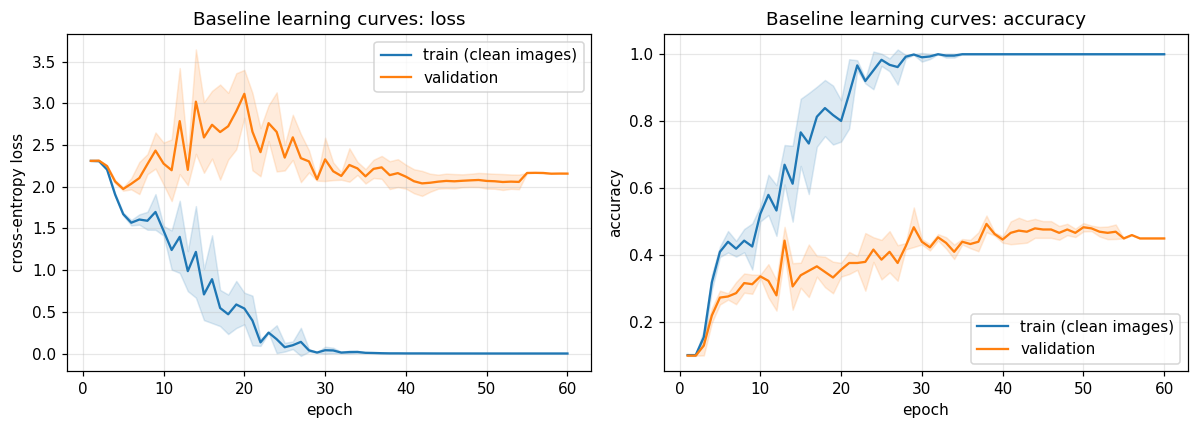

train - validation gap: 48.3 points   |   clean-test - shifted-test gap: 23.5 points   |   chance = 10.0%


In [15]:
base_runs = run_all(
    TAGS["No augmentation"],
    CFG["No augmentation"]
)

rows = [
    ("Train (400, clean)", [r["train_acc"] for r in base_runs]),
    ("Validation (100)", [r["val_acc"] for r in base_runs]),
    ("Clean test (10,000)", [r["clean_acc"] for r in base_runs]),
    ("Shifted test (10,000)", [r["shift_acc"] for r in base_runs])
]

dfA = pd.DataFrame(
    [(name, ms(values)) for name, values in rows],
    columns=["Split", "Accuracy % (mean ± std, 3 seeds)"]
)

print(dfA.to_string(index=False))


def curve(ax, runs, key, label, color, ls="-"):
    length = max(len(run["hist"][key]) for run in runs)
    values = np.full((len(runs), length), np.nan)

    for i, run in enumerate(runs):
        history = run["hist"][key]
        values[i, :len(history)] = history

    mean = np.nanmean(values, axis=0)
    std = np.nanstd(values, axis=0)
    epochs = np.arange(1, length + 1)

    ax.plot(epochs, mean, ls, color=color, label=label)
    ax.fill_between(
        epochs,
        mean - std,
        mean + std,
        color=color,
        alpha=0.15
    )


fig, ax = plt.subplots(1, 2, figsize=(11, 4))

curve(
    ax[0], base_runs, "train_loss",
    "train (clean images)", "tab:blue"
)
curve(
    ax[0], base_runs, "val_loss",
    "validation", "tab:orange"
)

ax[0].set(
    xlabel="epoch",
    ylabel="cross-entropy loss",
    title="Baseline learning curves: loss"
)
ax[0].legend()

curve(
    ax[1], base_runs, "train_acc",
    "train (clean images)", "tab:blue"
)
curve(
    ax[1], base_runs, "val_acc",
    "validation", "tab:orange"
)

ax[1].set(
    xlabel="epoch",
    ylabel="accuracy",
    title="Baseline learning curves: accuracy"
)
ax[1].legend()

plt.tight_layout()
plt.show()


gap_cs = np.mean([
    run["clean_acc"] - run["shift_acc"]
    for run in base_runs
]) * 100

gap_tv = np.mean([
    run["train_acc"] - run["val_acc"]
    for run in base_runs
]) * 100

print(
    f"train - validation gap: {gap_tv:.1f} points   |   "
    f"clean-test - shifted-test gap: {gap_cs:.1f} points   |   "
    f"chance = 10.0%"
)

In [16]:
GP = CFG["Geometric + photometric"]

side_cfgs = {
    "Default (rotation ±20°, no vertical flip)": (
        TAGS["Geometric + photometric"],
        GP
    ),
    "Default + vertical flip": (
        "side_vflip",
        make_cfg(geo=True, photo=True, vflip=True)
    ),
    "Rotation ±90° instead of ±20°": (
        "side_rot90",
        make_cfg(geo=True, photo=True, rot=90.0)
    ),
    "Too much of everything (rot ±90°, cutout, cutmix, all colour ops)": (
        "side_toomuch",
        make_cfg(
            geo=True,
            photo=True,
            cutout=True,
            cutmix=True,
            ls=0.1,
            rot=90.0,
            vflip=True
        )
    )
}

side_runs = {
    name: run_all(tag, cfg)
    for name, (tag, cfg) in side_cfgs.items()
}

dfB = pd.DataFrame(
    [
        (
            name,
            ms([r["val_acc"] for r in runs]),
            ms([r["clean_acc"] for r in runs]),
            ms([r["shift_acc"] for r in runs])
        )
        for name, runs in side_runs.items()
    ],
    columns=[
        "Configuration (geo + photo base)",
        "Val acc %",
        "Clean test %",
        "Shifted test %"
    ]
)

print(dfB.to_string(index=False))

  [abl3 | seed 0] best epoch 53/60 | train 0.735 val 0.580 clean 0.441 shifted 0.231 | 8s
  [abl3 | seed 1] best epoch 41/60 | train 0.642 val 0.560 clean 0.406 shifted 0.206 | 8s
  [abl3 | seed 2] best epoch 52/60 | train 0.750 val 0.590 clean 0.439 shifted 0.232 | 7s
  [side_vflip | seed 0] best epoch 46/60 | train 0.553 val 0.490 clean 0.363 shifted 0.197 | 8s
  [side_vflip | seed 1] best epoch 54/60 | train 0.613 val 0.510 clean 0.406 shifted 0.190 | 7s
  [side_vflip | seed 2] best epoch 48/60 | train 0.555 val 0.520 clean 0.385 shifted 0.186 | 9s
  [side_rot90 | seed 0] best epoch 60/60 | train 0.510 val 0.460 clean 0.341 shifted 0.186 | 8s
  [side_rot90 | seed 1] best epoch 40/60 | train 0.502 val 0.400 clean 0.332 shifted 0.175 | 7s
  [side_rot90 | seed 2] best epoch 56/60 | train 0.545 val 0.430 clean 0.345 shifted 0.189 | 8s
  [side_toomuch | seed 0] best epoch 12/37 | train 0.270 val 0.330 clean 0.244 shifted 0.138 | 5s
  [side_toomuch | seed 1] best epoch 59/60 | train 0.407

  [hp_lr0.02_wd0.0005_d0.3 | seed 0] best epoch 53/60 | train 0.548 val 0.440 (test sets not evaluated) | 7s
  [hp_lr0.02_wd0.003_d0.3 | seed 0] best epoch 53/60 | train 0.555 val 0.490 (test sets not evaluated) | 8s
  [hp_lr0.05_wd0.0005_d0.3 | seed 0] best epoch 54/60 | train 0.610 val 0.540 (test sets not evaluated) | 8s
  [hp_lr0.05_wd0.003_d0.3 | seed 0] best epoch 53/60 | train 0.585 val 0.530 (test sets not evaluated) | 7s
  [hp_lr0.1_wd0.0005_d0.3 | seed 0] best epoch 56/60 | train 0.575 val 0.530 (test sets not evaluated) | 8s
  [hp_lr0.1_wd0.003_d0.3 | seed 0] best epoch 56/60 | train 0.575 val 0.560 (test sets not evaluated) | 7s
  [hp_lr0.1_wd0.003_d0.1 | seed 0] best epoch 51/60 | train 0.562 val 0.560 (test sets not evaluated) | 8s
  [hp_lr0.1_wd0.003_d0.5 | seed 0] best epoch 54/60 | train 0.560 val 0.560 (test sets not evaluated) | 8s
  lr     wd  drop  val_acc  val_loss
0.10 0.0030   0.3     0.56  1.521526
0.10 0.0030   0.5     0.56  1.523451
0.10 0.0030   0.1     0.56

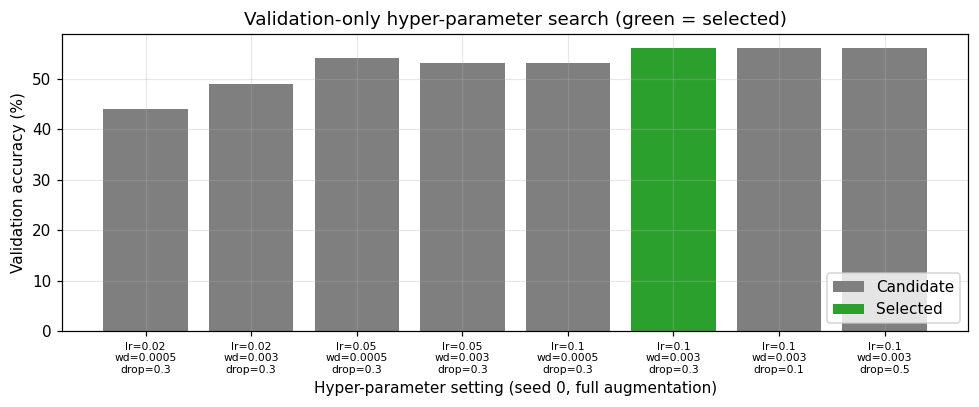

In [17]:
FULL = CFG["+ CutMix + label smoothing"]


def hp_run(hp):
    tag = f"hp_lr{hp['lr']}_wd{hp['wd']}_d{hp['drop']}"

    result = run_cached(
        tag,
        FULL,
        0,
        hp,
        eval_test=False
    )

    return {
        "lr": hp["lr"],
        "wd": hp["wd"],
        "drop": hp["drop"],
        "val_acc": result["val_acc"],
        "val_loss": result["val_loss"],
        "hp": hp
    }


stage1 = [
    hp_run({
        "lr": lr,
        "wd": wd,
        "drop": 0.3,
        "patience": 25
    })
    for lr in (0.02, 0.05, 0.1)
    for wd in (5e-4, 3e-3)
]

b1 = max(
    stage1,
    key=lambda t: (t["val_acc"], -t["val_loss"])
)

stage2 = [
    hp_run({
        "lr": b1["lr"],
        "wd": b1["wd"],
        "drop": drop,
        "patience": 25
    })
    for drop in (0.1, 0.5)
    if drop != b1["drop"]
]

allhp = stage1 + stage2

best = max(
    allhp,
    key=lambda t: (t["val_acc"], -t["val_loss"])
)

best_hp = best["hp"]

dfC = pd.DataFrame([
    {
        key: result[key]
        for key in ("lr", "wd", "drop", "val_acc", "val_loss")
    }
    for result in allhp
]).sort_values(
    ["val_acc", "val_loss"],
    ascending=[False, True]
)

print(dfC.to_string(index=False))
print("\nSelected hyper-parameters (validation only):", best_hp)


fig, ax = plt.subplots(figsize=(9, 3.8))

labels = [
    f"lr={result['lr']}\nwd={result['wd']}\ndrop={result['drop']}"
    for result in allhp
]

bar_colors = [
    "tab:green" if result is best else "tab:gray"
    for result in allhp
]

bars = ax.bar(
    range(len(allhp)),
    [100 * result["val_acc"] for result in allhp],
    color=bar_colors
)

ax.set_xticks(range(len(allhp)))
ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel("Validation accuracy (%)")
ax.set_xlabel(
    "Hyper-parameter setting (seed 0, full augmentation)"
)
ax.set_title(
    "Validation-only hyper-parameter search (green = selected)"
)

ax.legend(
    [bars[0], bars[allhp.index(best)]],
    ["Candidate", "Selected"],
    loc="lower right"
)

plt.tight_layout()
plt.show()

  [abl0 | seed 0] best epoch 38/60 | train 1.000 val 0.500 clean 0.416 shifted 0.184 | 11s (loaded from results/)
  [abl0 | seed 1] best epoch 29/54 | train 1.000 val 0.530 clean 0.420 shifted 0.173 | 5s (loaded from results/)
  [abl0 | seed 2] best epoch 29/54 | train 1.000 val 0.520 clean 0.411 shifted 0.184 | 5s (loaded from results/)
  [abl1 | seed 0] best epoch 45/60 | train 0.920 val 0.520 clean 0.407 shifted 0.170 | 8s
  [abl1 | seed 1] best epoch 51/60 | train 0.962 val 0.490 clean 0.416 shifted 0.177 | 6s
  [abl1 | seed 2] best epoch 46/60 | train 0.905 val 0.510 clean 0.412 shifted 0.190 | 6s
  [abl2 | seed 0] best epoch 51/60 | train 1.000 val 0.490 clean 0.354 shifted 0.188 | 7s
  [abl2 | seed 1] best epoch 55/60 | train 1.000 val 0.490 clean 0.386 shifted 0.190 | 7s
  [abl2 | seed 2] best epoch 36/60 | train 0.978 val 0.440 clean 0.312 shifted 0.164 | 7s
  [abl3 | seed 0] best epoch 53/60 | train 0.735 val 0.580 clean 0.441 shifted 0.231 | 8s (loaded from results/)
  [abl3

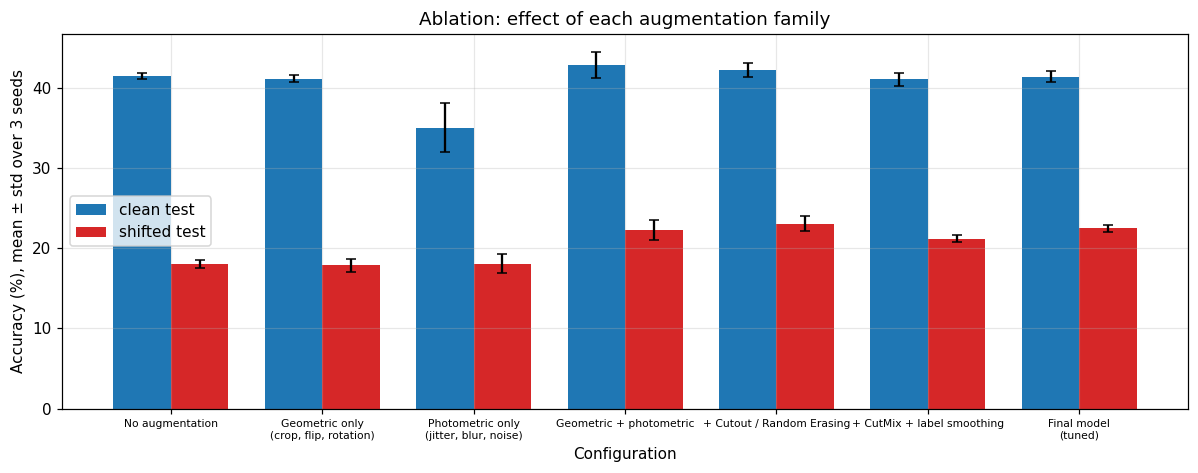


Shifted-test accuracy (%) per corruption subset (mean of 3 seeds):
                         Configuration strong rotation (|angle| > 15°) mild rotation (|angle| ≤ 15°) dark or bright (factor <0.75 or >1.25) low contrast (factor < 0.8) channel-swapped colours intact blurred noisy
                       No augmentation                            16.8                          18.8                                   17.4                        15.4            16.0           20.1    15.9  18.4
 Geometric only (crop, flip, rotation)                            17.0                          18.4                                   16.9                        16.5            15.2           20.6    16.3  17.8
Photometric only (jitter, blur, noise)                            16.1                          19.3                                   17.4                        17.3            17.2           18.9    17.8  17.0
               Geometric + photometric                            21.1          

In [18]:
final_same = best_hp == HP_DEFAULT

abl = {
    name: run_all(TAGS[name], cfg)
    for name, cfg in CFG.items()
}

abl["Final model (tuned)"] = (
    abl["+ CutMix + label smoothing"]
    if final_same
    else run_all("final", FULL, best_hp)
)


dfD = pd.DataFrame(
    [
        (
            name,
            ms([r["val_acc"] for r in runs]),
            ms([r["clean_acc"] for r in runs]),
            ms([r["shift_acc"] for r in runs])
        )
        for name, runs in abl.items()
    ],
    columns=[
        "Configuration",
        "Val Acc %",
        "Clean Test %",
        "Shifted Test %"
    ]
)

print(dfD.to_string(index=False))

dfD.to_csv(
    os.path.join(OUT_DIR, "ablation_table.csv"),
    index=False
)


names = list(abl)
x = np.arange(len(names))
w = 0.38

cm = [
    100 * np.mean([r["clean_acc"] for r in abl[name]])
    for name in names
]
cs = [
    100 * np.std([r["clean_acc"] for r in abl[name]])
    for name in names
]

sm = [
    100 * np.mean([r["shift_acc"] for r in abl[name]])
    for name in names
]
ss = [
    100 * np.std([r["shift_acc"] for r in abl[name]])
    for name in names
]

fig, ax = plt.subplots(figsize=(11, 4.4))

ax.bar(
    x - w / 2,
    cm,
    w,
    yerr=cs,
    capsize=3,
    label="clean test",
    color="tab:blue"
)

ax.bar(
    x + w / 2,
    sm,
    w,
    yerr=ss,
    capsize=3,
    label="shifted test",
    color="tab:red"
)

ax.set_xticks(x)
ax.set_xticklabels(
    [name.replace(" (", "\n(").replace("+ ", "+ ") for name in names],
    fontsize=7,
    rotation=0
)

ax.set_ylabel("Accuracy (%), mean ± std over 3 seeds")
ax.set_xlabel("Configuration")
ax.set_title("Ablation: effect of each augmentation family")
ax.legend()

plt.tight_layout()
plt.show()


# Accuracy of the shifted test split by corruption type

Ys = Yshift.numpy()

if shift_meta is not None:
    mt = shift_meta

    subsets = {
        "strong rotation (|angle| > 15°)": np.abs(mt["angle"]) > 15,
        "mild rotation (|angle| ≤ 15°)": np.abs(mt["angle"]) <= 15,
        "dark or bright (factor <0.75 or >1.25)": (
            (mt["bright"] < 0.75) | (mt["bright"] > 1.25)
        ),
        "low contrast (factor < 0.8)": mt["contrast"] < 0.8,
        "channel-swapped": mt["swapped"],
        "colours intact": ~mt["swapped"],
        "blurred": mt["blur"],
        "noisy": mt["noise"]
    }

    rows = []

    for name in names:
        row = {"Configuration": name}

        for subset_name, mask in subsets.items():
            accuracy = np.mean([
                (run["shift_pred"][mask] == Ys[mask]).mean()
                for run in abl[name]
            ])

            row[subset_name] = f"{100 * accuracy:.1f}"

        rows.append(row)

    dfSub = pd.DataFrame(rows)

    pd.set_option("display.width", 250)
    pd.set_option("display.max_columns", 30)

    print(
        "\nShifted-test accuracy (%) per corruption subset "
        "(mean of 3 seeds):"
    )
    print(dfSub.to_string(index=False))

    dfSub.to_csv(
        os.path.join(OUT_DIR, "subset_accuracy.csv"),
        index=False
    )

else:
    print(
        "\n(Per-corruption breakdown skipped: "
        "no corruption metadata for the official shifted test)"
    )


# Gain of each change compared with the configuration it was added to:
# Geometric only / photometric only / geo + photo -> No augmentation
# Cutout -> geo + photo
# CutMix -> geo + photo + cutout

ref = {
    1: 0,
    2: 0,
    3: 0,
    4: 3,
    5: 4
}

step = [
    (names[i], sm[i] - sm[ref[i]])
    for i in range(1, 6)
]

base_sh = sm[0]

print(
    "\nShifted-test gain over 'No augmentation':",
    {
        name: round(sm[i] - base_sh, 1)
        for i, name in enumerate(names)
        if i > 0
    }
)

print(
    "Step-by-step change of the stacked pipeline "
    "(geo + photo -> + cutout -> + cutmix):",
    [(name, round(gain, 1)) for name, gain in step[3:]]
)

     class accuracy % (mean ± std)
  airplane              24.5 ± 5.0
automobile              24.2 ± 7.8
      bird              22.6 ± 4.4
       cat              11.0 ± 1.2
      deer              33.8 ± 2.9
       dog              16.2 ± 5.7
      frog              20.9 ± 3.7
     horse              17.0 ± 5.8
      ship              26.9 ± 8.3
     truck              28.1 ± 7.0


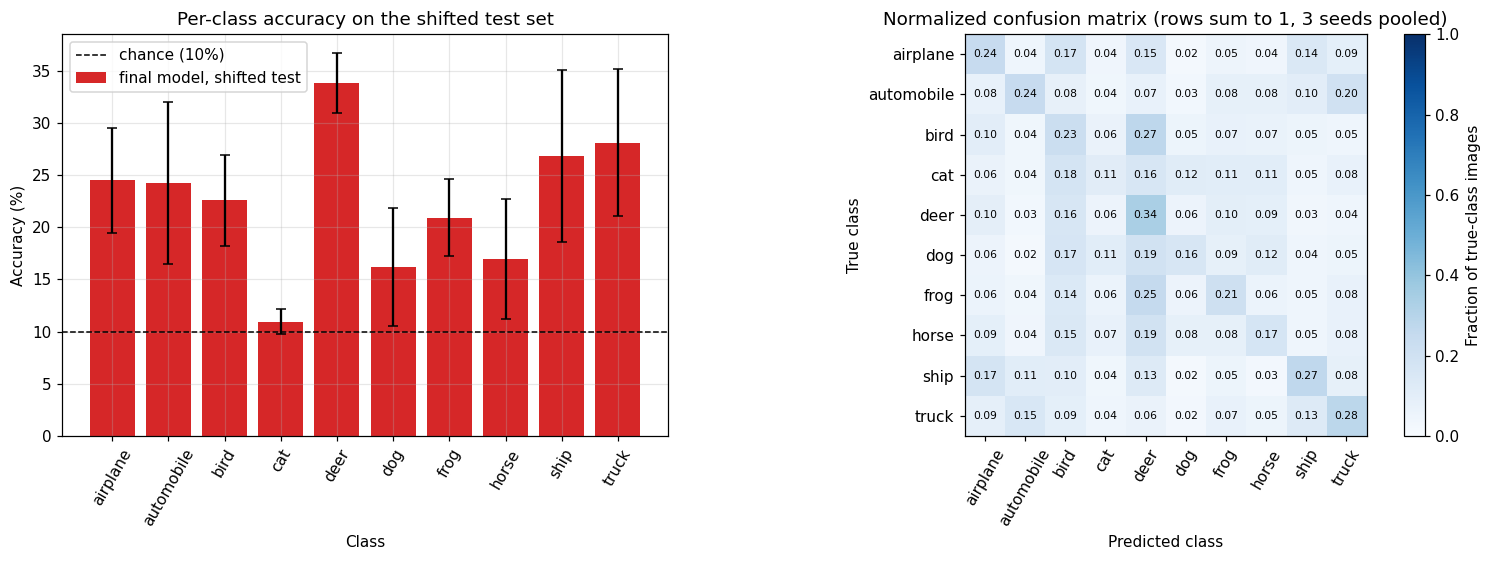

Most confused (true -> predicted, fraction of the true class):
         bird -> deer       0.27
         frog -> deer       0.25
   automobile -> truck      0.20
        horse -> deer       0.19
          dog -> deer       0.19
          cat -> bird       0.18
     airplane -> bird       0.17
         ship -> airplane   0.17


In [19]:
final_runs = abl["Final model (tuned)"]
mt = shift_meta


def load_model(r):
    model = Net(r["hp"]["drop"]).to(device)
    model.load_state_dict(r["state"])
    return model.eval()


final_models = [load_model(r) for r in final_runs]


# ---- 1. Per-class accuracy and normalized confusion matrix ----
# Predictions are pooled over the 3 seeds.

pc = np.array([
    [
        (r["shift_pred"][Ys == c] == c).mean()
        for c in range(NUM_CLASSES)
    ]
    for r in final_runs
]) * 100

dfPC = pd.DataFrame({
    "class": CLASSES,
    "accuracy % (mean ± std)": [
        f"{pc[:, c].mean():.1f} ± {pc[:, c].std():.1f}"
        for c in range(NUM_CLASSES)
    ]
})

print(dfPC.to_string(index=False))


conf = np.zeros((NUM_CLASSES, NUM_CLASSES))

for r in final_runs:
    for true_label, predicted_label in zip(Ys, r["shift_pred"]):
        conf[true_label, predicted_label] += 1

conf_n = conf / conf.sum(axis=1, keepdims=True)


fig, ax = plt.subplots(
    1,
    2,
    figsize=(14, 5.2),
    gridspec_kw={"width_ratios": [1, 1.25]}
)

ax[0].bar(
    CLASSES,
    pc.mean(axis=0),
    yerr=pc.std(axis=0),
    capsize=3,
    color="tab:red",
    label="final model, shifted test"
)

ax[0].axhline(
    10,
    color="k",
    linestyle="--",
    linewidth=1,
    label="chance (10%)"
)

ax[0].set_xlabel("Class")
ax[0].set_ylabel("Accuracy (%)")
ax[0].set_title("Per-class accuracy on the shifted test set")
ax[0].tick_params(axis="x", rotation=60)
ax[0].legend()


im = ax[1].imshow(
    conf_n,
    cmap="Blues",
    vmin=0,
    vmax=1
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax[1].text(
            j,
            i,
            f"{conf_n[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if conf_n[i, j] > 0.5 else "black"
        )

ax[1].set_xticks(range(NUM_CLASSES))
ax[1].set_xticklabels(CLASSES, rotation=60)

ax[1].set_yticks(range(NUM_CLASSES))
ax[1].set_yticklabels(CLASSES)

ax[1].set_xlabel("Predicted class")
ax[1].set_ylabel("True class")
ax[1].set_title(
    "Normalized confusion matrix (rows sum to 1, 3 seeds pooled)"
)
ax[1].grid(False)

plt.colorbar(
    im,
    ax=ax[1],
    label="Fraction of true-class images"
)

plt.tight_layout()
plt.show()


off = [
    (conf_n[i, j], CLASSES[i], CLASSES[j])
    for i in range(NUM_CLASSES)
    for j in range(NUM_CLASSES)
    if i != j
]

print("Most confused (true -> predicted, fraction of the true class):")

for value, true_class, predicted_class in sorted(
    off,
    reverse=True
)[:8]:
    print(
        f"   {true_class:>10s} -> "
        f"{predicted_class:<10s} {value:.2f}"
    )

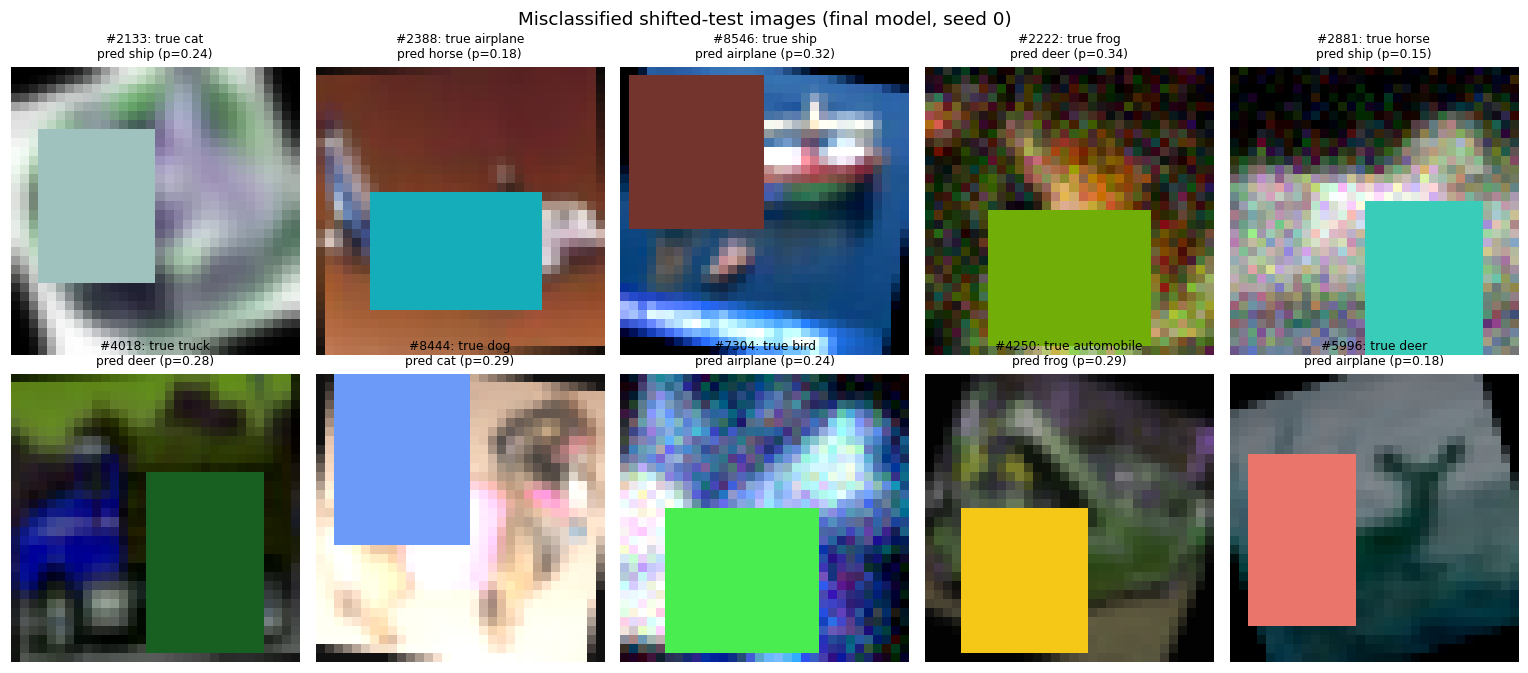

 image       true predicted confidence                                  corruptions on this image
  2133        cat      ship       0.24      rotated +19°, blurred, channels swapped, 22% occluded
  2388   airplane     horse       0.18                             channels swapped, 24% occluded
  8546       ship  airplane       0.32                               bright (x1.49), 25% occluded
  2222       frog      deer       0.34                               blurred, noisy, 26% occluded
  2881      horse      ship       0.15             blurred, noisy, channels swapped, 22% occluded
  4018      truck      deer       0.28               dark (x0.61), channels swapped, 25% occluded
  8444        dog       cat       0.29                               bright (x1.31), 28% occluded
  7304       bird  airplane       0.24             blurred, noisy, channels swapped, 27% occluded
  4250 automobile      frog       0.29 rotated -22°, dark (x0.65), channels swapped, 22% occluded
  5996       deer  a

In [20]:
m0 = final_models[0]
pred0 = final_runs[0]["shift_pred"]

wrong = np.where(pred0 != Ys)[0]

rs = np.random.RandomState(0)
rs.shuffle(wrong)

chosen = []
seen = set()

for i in wrong:
    if Ys[i] not in seen:
        chosen.append(int(i))
        seen.add(Ys[i])

    if len(chosen) == 10:
        break


with torch.no_grad():
    probs = F.softmax(
        m0(Xsh_n[chosen]),
        dim=1
    ).cpu().numpy()


def describe(i):
    features = []

    if abs(mt["angle"][i]) > 15:
        features.append(f"rotated {mt['angle'][i]:+.0f}°")

    if mt["bright"][i] < 0.75:
        features.append(f"dark (x{mt['bright'][i]:.2f})")

    if mt["bright"][i] > 1.25:
        features.append(f"bright (x{mt['bright'][i]:.2f})")

    if mt["contrast"][i] < 0.8:
        features.append(f"low contrast (x{mt['contrast'][i]:.2f})")

    if mt["blur"][i]:
        features.append("blurred")

    if mt["noise"][i]:
        features.append("noisy")

    if mt["swapped"][i]:
        features.append("channels swapped")

    features.append(f"{100 * mt['occ_area'][i]:.0f}% occluded")

    return ", ".join(features)


if shift_meta is None:
    describe = lambda i: "(no corruption metadata)"


fig, ax = plt.subplots(2, 5, figsize=(14, 6.2))

for k, i in enumerate(chosen):
    a = ax[k // 5, k % 5]

    a.imshow(Xshift[i].permute(1, 2, 0).cpu())
    a.axis("off")

    a.set_title(
        f"#{i}: true {CLASSES[Ys[i]]}\n"
        f"pred {CLASSES[pred0[i]]} "
        f"(p={probs[k, pred0[i]]:.2f})",
        fontsize=8
    )

fig.suptitle(
    "Misclassified shifted-test images (final model, seed 0)"
)

plt.tight_layout()
plt.show()


dfMis = pd.DataFrame(
    [
        (
            i,
            CLASSES[Ys[i]],
            CLASSES[pred0[i]],
            f"{probs[k, pred0[i]]:.2f}",
            describe(i)
        )
        for k, i in enumerate(chosen)
    ],
    columns=[
        "image",
        "true",
        "predicted",
        "confidence",
        "corruptions on this image"
    ]
)

pd.set_option("display.max_colwidth", 120)

print(dfMis.to_string(index=False))

  [ctrl_nocolor | seed 0] best epoch 55/60 | train 0.702 val 0.440 clean 0.418 shifted 0.197 | 8s
  [ctrl_nocolor | seed 1] best epoch 49/60 | train 0.650 val 0.500 clean 0.405 shifted 0.188 | 8s
  [ctrl_nocolor | seed 2] best epoch 52/60 | train 0.658 val 0.500 clean 0.391 shifted 0.189 | 9s
                                             Model Clean test % Hidden corruption only % …on the swapped half only % Grayscale test % Colour-inverted test % Drop clean→hidden (pts)
                        No augmentation (baseline)   41.5 ± 0.4               35.9 ± 0.1                  29.5 ± 0.5       34.8 ± 0.5             12.0 ± 0.3                     5.7
    Final model (with grayscale + channel shuffle)   41.4 ± 0.7               36.5 ± 0.6                  31.1 ± 0.6       36.0 ± 0.3             13.4 ± 0.7                     4.9
Control: same, WITHOUT grayscale + channel shuffle   40.5 ± 1.1               31.6 ± 0.5                  21.7 ± 0.3       29.6 ± 1.2              8.5 ± 1.0       

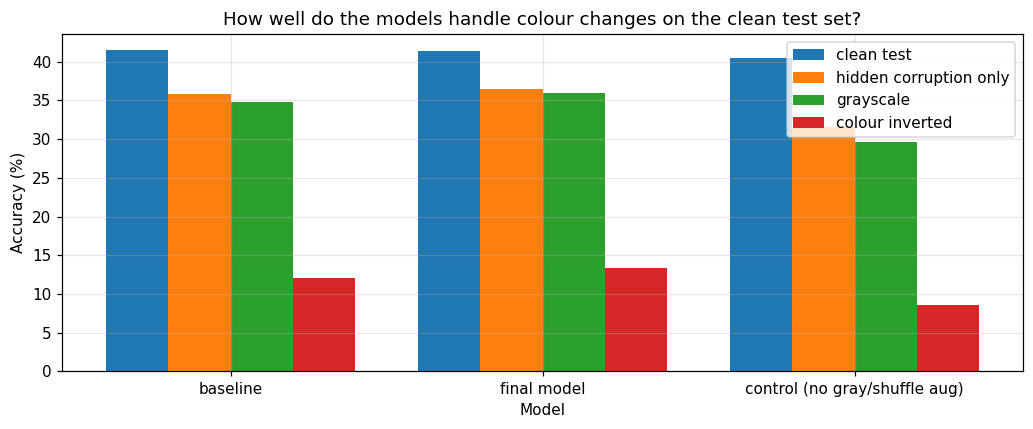

In [21]:
def acc_on(model, X):
    return evaluate(model, X, Yclean)[0]


# Colour changes not used directly during training
inv_n = dv(norm(1 - Xclean))

gray_n = dv(norm(
    (
        0.299 * Xclean[:, 0:1]
        + 0.587 * Xclean[:, 1:2]
        + 0.114 * Xclean[:, 2:3]
    ).expand(-1, 3, -1, -1)
))

swap_mask = (
    shift_meta["swapped"]
    if shift_meta is not None
    else np.ones(len(Yclean), dtype=bool)
)


# Control: same pipeline without grayscale and channel-shuffle augmentation
ctrl_cfg = dict(FULL, color_inv=False)

ctrl_runs = run_all(
    "ctrl_nocolor",
    ctrl_cfg,
    best_hp
)


groups = {
    "No augmentation (baseline)": base_runs,
    "Final model (with grayscale + channel shuffle)": final_runs,
    "Control: same, WITHOUT grayscale + channel shuffle": ctrl_runs
}

rows = []

for name, runs in groups.items():
    models = [load_model(run) for run in runs]

    clean_acc = [
        acc_on(model, Xcl_n)
        for model in models
    ]

    hidden_acc = [
        acc_on(model, Xhid_n)
        for model in models
    ]

    swapped_acc = [
        evaluate(
            model,
            Xhid_n[torch.from_numpy(swap_mask).to(device)],
            Yclean[torch.from_numpy(swap_mask)]
        )[0]
        for model in models
    ]

    inverted_acc = [
        acc_on(model, inv_n)
        for model in models
    ]

    grayscale_acc = [
        acc_on(model, gray_n)
        for model in models
    ]

    rows.append((
        name,
        ms(clean_acc),
        ms(hidden_acc),
        ms(swapped_acc),
        ms(grayscale_acc),
        ms(inverted_acc),
        f"{100 * (np.mean(clean_acc) - np.mean(hidden_acc)):.1f}"
    ))


dfH = pd.DataFrame(
    rows,
    columns=[
        "Model",
        "Clean test %",
        "Hidden corruption only %",
        "…on the swapped half only %",
        "Grayscale test %",
        "Colour-inverted test %",
        "Drop clean→hidden (pts)"
    ]
)

print(dfH.to_string(index=False))

dfH.to_csv(
    os.path.join(OUT_DIR, "hidden_corruption.csv"),
    index=False
)


fig, ax = plt.subplots(figsize=(9.5, 4))

x = np.arange(3)
w = 0.2

metrics = [
    ("Clean test %", "clean test"),
    ("Hidden corruption only %", "hidden corruption only"),
    ("Grayscale test %", "grayscale"),
    ("Colour-inverted test %", "colour inverted")
]

for k, (column, label) in enumerate(metrics):
    values = [
        float(value.split(" ")[0])
        for value in dfH[column]
    ]

    ax.bar(
        x + (k - 1.5) * w,
        values,
        w,
        label=label
    )


ax.set_xticks(x)
ax.set_xticklabels([
    "baseline",
    "final model",
    "control (no gray/shuffle aug)"
])

ax.set_xlabel("Model")
ax.set_ylabel("Accuracy (%)")
ax.set_title(
    "How well do the models handle colour changes on the clean test set?"
)
ax.legend()

plt.tight_layout()
plt.show()

 views N Shifted-test acc % (mean ± std) change vs N=1 (pts) inference time (10k images) relative cost
       1                      22.5 ± 0.4                +0.0                      0.25 s          1.0x
       2                      22.5 ± 0.3                -0.0                      0.46 s          1.9x
       4                      22.3 ± 0.4                -0.3                      0.94 s          3.8x
       8                      22.1 ± 0.2                -0.4                      1.90 s          7.6x


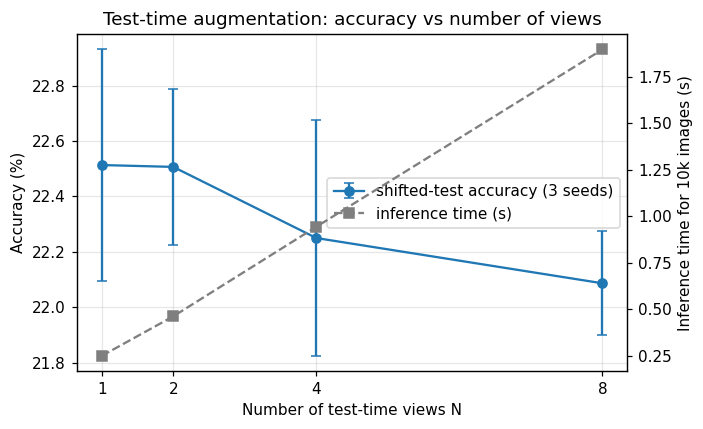

In [22]:
def view_batch(xraw, k):
    n = xraw.size(0)

    z = torch.zeros(n, device=xraw.device)
    o = torch.ones(n, device=xraw.device)
    s = 2 / 16

    specs = [
        (0, 0, 1),
        (0, 0, -1),
        (s, 0, 1),
        (-s, 0, 1),
        (0, s, 1),
        (0, -s, 1),
        (s, 0, -1),
        (-s, 0, -1)
    ]

    tx, ty, fl = specs[k]

    return (
        xraw
        if k == 0
        else affine_batch(
            xraw,
            z,
            o,
            z + tx,
            z + ty,
            o * fl
        )
    )


def tta_probs(model, Xraw, n_views, bs=1000):
    model.eval()
    out = []

    with torch.no_grad():
        for i in range(0, len(Xraw), bs):
            xb = Xraw[i:i + bs]
            p = 0

            for k in range(n_views):
                transformed = view_batch(xb, k)
                normalized = (transformed - MEAN_d) / STD_d

                p = p + F.softmax(
                    model(normalized),
                    dim=1
                )

            out.append((p / n_views).cpu())

    return torch.cat(out)


Nviews = [1, 2, 4, 8]

res = {n: [] for n in Nviews}
times = {n: [] for n in Nviews}

for model in final_models:
    for n in Nviews:
        t0 = time.time()

        p = tta_probs(model, Xsh_raw, n)

        times[n].append(time.time() - t0)

        accuracy = (p.argmax(1) == Yshift).float().mean().item()
        res[n].append(accuracy)


dfF = pd.DataFrame(
    [
        (
            n,
            ms(res[n]),
            f"{100 * (np.mean(res[n]) - np.mean(res[1])):+.1f}",
            f"{np.mean(times[n]):.2f} s",
            f"{np.mean(times[n]) / np.mean(times[1]):.1f}x"
        )
        for n in Nviews
    ],
    columns=[
        "views N",
        "Shifted-test acc % (mean ± std)",
        "change vs N=1 (pts)",
        "inference time (10k images)",
        "relative cost"
    ]
)

print(dfF.to_string(index=False))


fig, ax = plt.subplots(figsize=(6.5, 4))

mean_acc = [
    100 * np.mean(res[n])
    for n in Nviews
]

std_acc = [
    100 * np.std(res[n])
    for n in Nviews
]

ax.errorbar(
    Nviews,
    mean_acc,
    yerr=std_acc,
    marker="o",
    capsize=3,
    label="shifted-test accuracy (3 seeds)"
)

ax.set_xticks(Nviews)
ax.set_xlabel("Number of test-time views N")
ax.set_ylabel("Accuracy (%)")
ax.set_title(
    "Test-time augmentation: accuracy vs number of views"
)


ax2 = ax.twinx()

ax2.plot(
    Nviews,
    [np.mean(times[n]) for n in Nviews],
    "s--",
    color="tab:gray",
    label="inference time (s)"
)

ax2.set_ylabel("Inference time for 10k images (s)")
ax2.grid(False)


h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()

ax.legend(
    h1 + h2,
    l1 + l2,
    loc="center right"
)

plt.tight_layout()
plt.show()

In [24]:
import json

In [25]:
fin = abl["Final model (tuned)"]

fin_sh = [r["shift_acc"] for r in fin]
fin_cl = [r["clean_acc"] for r in fin]
fin_va = [r["val_acc"] for r in fin]

bs_ = [
    r["shift_acc"]
    for r in abl["No augmentation"]
]


summary = {
    "seeds": SEEDS,
    "params": int(n_params),
    "best_hp": best_hp,
    "final_shift": ms(fin_sh),
    "final_clean": ms(fin_cl),
    "final_val": ms(fin_va),
    "baseline_shift": ms(bs_),
    "baseline_clean": ms([
        r["clean_acc"]
        for r in abl["No augmentation"]
    ]),
    "ablation": dfD.values.tolist(),
    "tta8": dfF.values.tolist()[-1],
    "hidden": dfH.values.tolist(),
    "gain_over_baseline": {
        name: round(sm[i] - sm[0], 1)
        for i, name in enumerate(names)
        if i > 0
    },
    "single_change_gain": {
        name: round(gain, 1)
        for name, gain in step
    }
}


summary_path = os.path.join(OUT_DIR, "summary.json")

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=1, default=str)


print(json.dumps(
    {
        key: summary[key]
        for key in (
            "params",
            "best_hp",
            "final_val",
            "final_clean",
            "final_shift",
            "baseline_shift",
            "gain_over_baseline",
            "single_change_gain"
        )
    },
    indent=1,
    default=str
))

{
 "params": 64402,
 "best_hp": {
  "lr": 0.1,
  "wd": 0.003,
  "drop": 0.3,
  "patience": 25
 },
 "final_val": "56.0 \u00b1 0.0",
 "final_clean": "41.4 \u00b1 0.7",
 "final_shift": "22.5 \u00b1 0.4",
 "baseline_shift": "18.0 \u00b1 0.5",
 "gain_over_baseline": {
  "Geometric only (crop, flip, rotation)": -0.1,
  "Photometric only (jitter, blur, noise)": 0.0,
  "Geometric + photometric": 4.3,
  "+ Cutout / Random Erasing": 5.0,
  "+ CutMix + label smoothing": 3.2,
  "Final model (tuned)": 4.5
 },
 "single_change_gain": {
  "Geometric only (crop, flip, rotation)": -0.1,
  "Photometric only (jitter, blur, noise)": 0.0,
  "Geometric + photometric": 4.3,
  "+ Cutout / Random Erasing": 0.8,
  "+ CutMix + label smoothing": -1.9
 }
}
